# 04 Models: baselines and fusion

This notebook trains the single-modality baselines and the fusion models, all scored on the validation set. The test set is only used once, in notebook 05.

Fusion methods compared (Week 4 and 5): early fusion (join the features, one classifier), late fusion (average the predictions of separate models), and two neural models, concat fusion and attention fusion. The neural models give every modality its own projection to the same size first, so the 1,280 image numbers can't dominate the ~60 tabular ones just by count. The neural models are run with 3 seeds each so I can tell real differences from random variation (Week 7).

In [ ]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# same folder setup as the other notebooks
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/airbnb_p22")
except ImportError:
    PROJECT_DIR = Path("airbnb_p22")

DATA_DIR = PROJECT_DIR / "data"
FEATURE_DIR = DATA_DIR / "features"
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR = PROJECT_DIR / "models"
PRED_DIR = RESULTS_DIR / "predictions"
for folder in (MODEL_DIR, PRED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

try:
    df = pd.read_parquet(DATA_DIR / "listings_clean.parquet")
    ids = np.load(FEATURE_DIR / "ids.npy")
    img_raw = np.load(FEATURE_DIR / "image_effnet_crop.npy")
    bert_raw = np.load(FEATURE_DIR / "text_bert.npy")
except OSError as e:
    raise RuntimeError(f"Run notebooks 02 and 03 first: {e}")
# the feature files must be in exactly the same row order as the table
assert (ids == df["id"].to_numpy()).all(), "feature rows don't match the listings table"

y = df["price_level"].cat.codes.to_numpy()   # 0 budget, 1 mid-range, 2 premium
CLASSES = list(df["price_level"].cat.categories)
split = df["split"].to_numpy()
tr, va, te = split == "train", split == "val", split == "test"
has_photo = df["has_photo"].to_numpy()
has_text = df["has_description"].to_numpy()
print(f"train {tr.sum():,}, val {va.sum():,}, test {te.sum():,}")

Mounted at /content/drive
Using: Tesla T4
train 13,082, val 2,896, test 2,830


## Tabular features

Numeric: guests, bedrooms, beds, bathrooms (pulled out of text like "1.5 shared baths", plus a shared flag), number of amenities, number of reviews (logged because it's very skewed), review score, and a flag for listings with no reviews yet. Categorical: room type, property type and area, one-hot encoded. Missing values get the training median, and the scaling and categories are learnt from the training set only. Property types with fewer than 50 training listings are grouped together.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

tab = pd.DataFrame(index=df.index)
for col in ["accommodates", "bedrooms", "beds"]:
    tab[col] = df[col]
# bathrooms_text looks like "1.5 shared baths" or "Half-bath", so pull out the
# number and whether it's shared
bath = df["bathrooms_text"].fillna("").str.lower()
tab["bathrooms"] = pd.to_numeric(bath.str.extract(r"([\d.]+)")[0], errors="coerce")
tab.loc[bath.str.contains("half") & tab["bathrooms"].isna(), "bathrooms"] = 0.5
tab["shared_bath"] = bath.str.contains("shared").astype(float)
tab["n_amenities"] = df["amenities"].fillna("[]").map(lambda s: len(json.loads(s)))
tab["log_reviews"] = np.log1p(df["number_of_reviews"])   # very skewed, so log it
tab["review_score"] = df["review_scores_rating"]
# new listings have no score yet, which is information in itself
tab["no_reviews"] = df["review_scores_rating"].isna().astype(float)
for col in ["room_type", "property_type", "neighbourhood_cleansed"]:
    tab[col] = df[col].fillna("unknown")

numeric = ["accommodates", "bedrooms", "beds", "bathrooms", "shared_bath",
           "n_amenities", "log_reviews", "review_score", "no_reviews"]
categorical = ["room_type", "property_type", "neighbourhood_cleansed"]
# Everything is fitted on the training set only (medians, means, categories).
# Rare property types (under 50 training listings) are grouped together.
tab_prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                          sparse_output=False), categorical),
])
tab_prep.fit(tab[tr])
X_tab = tab_prep.transform(tab).astype(np.float32)
print(f"Tabular features: {X_tab.shape[1]} "
      f"({len(numeric)} numeric, {X_tab.shape[1] - len(numeric)} one-hot)")
print(tab[numeric][tr].describe().T[["mean", "min", "max"]].round(2))

Tabular features: 62 (9 numeric, 53 one-hot)
               mean  min    max
accommodates   3.91  1.0  16.00
bedrooms       1.79  0.0  14.00
beds           2.25  1.0  26.00
bathrooms      1.45  0.0  15.00
shared_bath    0.13  0.0   1.00
n_amenities   38.47  0.0  90.00
log_reviews    2.58  0.0   6.95
review_score   4.72  1.0   5.00
no_reviews     0.15  0.0   1.00


## Text and image inputs

TF-IDF beat frozen BERT in notebook 03 (0.614 vs 0.559). The neural fusion models need a short dense vector though, not 20,000 sparse columns, so I also compress TF-IDF to 300 dimensions with truncated SVD (latent semantic analysis, Deerwester et al., 1990). Whichever dense version scores better on validation is used in all the fusion models.

Image features are the EfficientNet-B0 centre-crop features, which did best in notebook 03. All dense inputs are scaled with training statistics, and a missing photo or description is set to 0 (the training mean), so it carries no fake signal.

In [ ]:
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

texts = df["description_clean"].fillna("")
tfidf = TfidfVectorizer(min_df=5, max_features=20000, ngram_range=(1, 2))
tfidf.fit(texts[tr])
X_tfidf = tfidf.transform(texts)

# The neural fusion models need a short dense vector, not 20,000 sparse columns,
# so TF-IDF is compressed to 300 dimensions with truncated SVD (this is LSA).
# Fitted on training rows only.
svd = TruncatedSVD(n_components=min(300, X_tfidf.shape[1] - 1), random_state=SEED).fit(X_tfidf[tr])
tfidf_svd_raw = svd.transform(X_tfidf).astype(np.float32)
print(f"SVD keeps {svd.explained_variance_ratio_.sum():.1%} of the TF-IDF variance")


def scale_dense(X, present):
    # scale with training statistics, then set missing rows to 0 (the training
    # mean), so a missing photo or description carries no fake signal
    scaler = StandardScaler().fit(X[tr & present])
    out = scaler.transform(X).astype(np.float32)
    out[~present] = 0
    return out


X_img = scale_dense(img_raw, has_photo)
X_bert = scale_dense(bert_raw, has_text)
X_svd = scale_dense(tfidf_svd_raw, has_text)


def quick_f1(X, rows_tr, rows_va, C=0.1):
    clf = LogisticRegression(max_iter=3000, C=C).fit(X[rows_tr], y[rows_tr])
    return f1_score(y[rows_va], clf.predict(X[rows_va]), average="macro")


# pick the dense text input for fusion on validation, like notebook 03
text_options = {"BERT (768)": X_bert, "TF-IDF + SVD (300)": X_svd}
scores = {k: quick_f1(v, tr & has_text, va & has_text) for k, v in text_options.items()}
print("Validation macro F1 for the dense text options:", {k: round(v, 3) for k, v in scores.items()})
TEXT_NAME = max(scores, key=scores.get)
X_text = text_options[TEXT_NAME]
print("Using for fusion:", TEXT_NAME)

SVD keeps 34.3% of the TF-IDF variance
Validation macro F1 for the dense text options: {'BERT (768)': 0.559, 'TF-IDF + SVD (300)': 0.604}
Using for fusion: TF-IDF + SVD (300)


## Single-modality baselines

One logistic regression per modality: tabular, text (the full sparse TF-IDF, since logistic regression handles it fine) and image. A listing with no photo or no description gets a flat 1/3 for each class from that modality, meaning it has no opinion. I also train gradient boosted trees on the tabular data as a stronger, widely used model to compare against.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score


def metrics(y_true, prob):
    pred = prob.argmax(1)
    return {"accuracy": accuracy_score(y_true, pred),
            "macro F1": f1_score(y_true, pred, average="macro"),
            "macro precision": precision_score(y_true, pred, average="macro"),
            "macro recall": recall_score(y_true, pred, average="macro")}


def save_pred(name, prob):
    # probabilities for every listing, so notebook 05 can score the test set once
    try:
        np.save(PRED_DIR / f"{name}.npy", prob.astype(np.float32))
    except OSError as e:
        print(f"Couldn't save predictions for {name}: {e}")


UNIFORM = np.full(3, 1 / 3)
val_rows = []
unimodal = {}

# One logistic regression per modality. A listing with no photo or no text
# gets a flat 1/3 each, meaning "this modality has no opinion".
for name, X, present, C in [("tabular", X_tab, np.ones(len(df), bool), 1.0),
                            ("text TF-IDF", X_tfidf, has_text, 1.0),
                            ("image", X_img, has_photo, 0.1)]:
    t0 = time.time()
    clf = LogisticRegression(max_iter=3000, C=C).fit(X[tr & present], y[tr & present])
    prob = np.tile(UNIFORM, (len(df), 1))
    prob[present] = clf.predict_proba(X[present])
    unimodal[name] = (clf, prob)
    save_pred(f"lr_{name.replace(' ', '_')}", prob)
    val_rows.append({"model": f"LR {name}", "family": "single modality",
                     **metrics(y[va], prob[va]), "train s": time.time() - t0})

# a stronger tabular model as an "existing model" reference: gradient boosted trees
t0 = time.time()
hgb = HistGradientBoostingClassifier(random_state=SEED).fit(X_tab[tr], y[tr])
prob = hgb.predict_proba(X_tab)
save_pred("hgb_tabular", prob)
val_rows.append({"model": "Gradient boosting tabular", "family": "single modality",
                 **metrics(y[va], prob[va]), "train s": time.time() - t0})

pd.DataFrame(val_rows).set_index("model").round(3)

,family,accuracy,macro F1,macro precision,macro recall,train s
model,,,,,,
LR tabular,single modality,0.669,0.674,0.682,0.669,1.818
LR text TF-IDF,single modality,0.613,0.614,0.615,0.614,5.024
LR image,single modality,0.489,0.489,0.488,0.490,14.811
Gradient boosting tabular,single modality,0.665,0.669,0.673,0.666,1.548


## Early and late fusion

Early fusion joins the three feature sets into one long vector and trains one logistic regression, with the strength of regularisation (C) picked on validation. The image block is much bigger than the others, which is the dimension imbalance problem from Week 4.

Late fusion takes a weighted average of the three single-modality predictions. The weights are searched in steps of 0.05 on the validation set, so its validation score is a bit optimistic; the test set in notebook 05 is the fair comparison.

In [ ]:
import itertools

# EARLY FUSION: join the three feature sets into one long vector and train one
# logistic regression (Week 4). The has_photo / has_description flags let the
# model know when a block is just zeros. C is picked on validation.
X_early = np.hstack([X_tab, X_text, X_img,
                     has_photo[:, None].astype(np.float32),
                     has_text[:, None].astype(np.float32)])
print(f"Early fusion input: {X_early.shape[1]} dims "
      f"(tabular {X_tab.shape[1]}, text {X_text.shape[1]}, image {X_img.shape[1]})")
best = None
for C in [0.0001, 0.0003, 0.001, 0.003, 0.01]:
    t0 = time.time()
    clf = LogisticRegression(max_iter=3000, C=C).fit(X_early[tr], y[tr])
    prob = clf.predict_proba(X_early)
    f1 = f1_score(y[va], prob[va].argmax(1), average="macro")
    print(f"  C={C}: val macro F1 {f1:.3f}")
    if best is None or f1 > best[0]:
        best = (f1, C, clf, prob, time.time() - t0)
_, best_C, early_clf, early_prob, early_s = best
save_pred("early_fusion_lr", early_prob)
val_rows.append({"model": f"Early fusion LR (C={best_C})", "family": "fusion",
                 **metrics(y[va], early_prob[va]), "train s": early_s})

# LATE FUSION: weighted average of the three single-modality probabilities
# (Week 4). The weights are searched in steps of 0.05 on validation, so the
# validation score is a bit optimistic; the test set in notebook 05 is the fair check.
probs = [unimodal[m][1] for m in ["tabular", "text TF-IDF", "image"]]
best = None
for w_tab, w_text in itertools.product(np.arange(0, 1.01, 0.05), repeat=2):
    w_img = 1 - w_tab - w_text
    if w_img < -1e-9:
        continue
    prob = w_tab * probs[0] + w_text * probs[1] + w_img * probs[2]
    f1 = f1_score(y[va], prob[va].argmax(1), average="macro")
    if best is None or f1 > best[0]:
        best = (f1, (w_tab, w_text, max(w_img, 0)))
late_w = best[1]
late_prob = late_w[0] * probs[0] + late_w[1] * probs[1] + late_w[2] * probs[2]
save_pred("late_fusion_weighted", late_prob)
print(f"Late fusion weights: tabular {late_w[0]:.2f}, text {late_w[1]:.2f}, image {late_w[2]:.2f}")
val_rows.append({"model": "Late fusion (weighted average)", "family": "fusion",
                 **metrics(y[va], late_prob[va]), "train s": np.nan})
try:
    with open(RESULTS_DIR / "late_fusion_weights.json", "w") as f:
        json.dump({"tabular": late_w[0], "text": late_w[1], "image": late_w[2]}, f, indent=2)
except OSError as e:
    print(f"Couldn't save the late fusion weights: {e}")
pd.DataFrame(val_rows).set_index("model").round(3)

Early fusion input: 1644 dims (tabular 62, text 300, image 1280)
  C=0.0001: val macro F1 0.662
  C=0.0003: val macro F1 0.675
  C=0.001: val macro F1 0.672
  C=0.003: val macro F1 0.665
  C=0.01: val macro F1 0.654
Late fusion weights: tabular 0.55, text 0.40, image 0.05


,family,accuracy,macro F1,macro precision,macro recall,train s
model,,,,,,
LR tabular,single modality,0.669,0.674,0.682,0.669,1.818
LR text TF-IDF,single modality,0.613,0.614,0.615,0.614,5.024
LR image,single modality,0.489,0.489,0.488,0.490,14.811
Gradient boosting tabular,single modality,0.665,0.669,0.673,0.666,1.548
Early fusion LR (C=0.0003),fusion,0.673,0.675,0.677,0.673,7.100
Late fusion (weighted average),fusion,0.698,0.702,0.710,0.698,NaN


## Neural fusion models

Each modality goes through its own small layer that projects it to 128 numbers, so all three are the same size. Concat fusion joins the three projections and classifies them. Attention fusion learns a score for each modality, turns the scores into weights that add up to 1 (softmax), and classifies the weighted sum. The weights change per listing, so they also show which modality the model relies on (additive attention, as in the Week 4 practical). A missing photo or description is masked out so it gets no weight.

Training uses Adam with batches of 256 (the learning rate, weight decay, dropout and projection size are tuned in the next cell), and early stopping: if validation loss doesn't improve for 6 epochs, training stops and the best epoch's weights are kept (Week 7). During training, modality dropout hides the image or text 20% of the time, so the model learns to cope when one is missing (Week 6). Dropout inside the layers helps against overfitting (0.5 was chosen in the sweep).

In [ ]:
import torch.nn as nn

MODS = ["tabular", "text", "image"]
inputs = {"tabular": X_tab, "text": X_text, "image": X_img}
present = np.stack([np.ones(len(df), bool), has_text, has_photo], axis=1)


class FusionNet(nn.Module):
    # Each modality gets its own small projection to the same size (128), so the
    # 1,280 image numbers can't drown out the ~60 tabular ones just by count.
    #   mode="concat":    join the projections, then classify (neural early fusion)
    #   mode="attention": learn a weight per modality for every listing and take
    #                     the weighted sum (additive attention, like the Week 4 practical)
    def __init__(self, dims, mode, d=128, p_drop=0.3):
        super().__init__()
        self.mods, self.mode = list(dims), mode
        self.proj = nn.ModuleDict({m: nn.Sequential(nn.Linear(dims[m], d), nn.ReLU(),
                                                    nn.Dropout(p_drop)) for m in dims})
        if mode == "attention":
            self.score = nn.Sequential(nn.Linear(d, 64), nn.Tanh(), nn.Linear(64, 1))
            head_in = d
        else:
            head_in = d * len(dims)
        self.head = nn.Sequential(nn.Linear(head_in, 64), nn.ReLU(), nn.Dropout(p_drop),
                                  nn.Linear(64, 3))

    def forward(self, xs, mask):
        z = torch.stack([self.proj[m](xs[m]) for m in self.mods], dim=1)  # batch x modality x 128
        z = z * mask.unsqueeze(-1)   # a missing modality contributes nothing
        if self.mode == "attention":
            s = self.score(z).squeeze(-1).masked_fill(mask == 0, -1e9)
            weights = torch.softmax(s, dim=1)   # sums to 1 over the modalities present
            return self.head((weights.unsqueeze(-1) * z).sum(1)), weights
        return self.head(z.flatten(1)), None


def to_tensors(rows, mods):
    xs = {m: torch.tensor(inputs[m][rows], device=device) for m in mods}
    mask = torch.tensor(present[rows][:, [MODS.index(m) for m in mods]],
                        dtype=torch.float32, device=device)
    return xs, mask, torch.tensor(y[rows], dtype=torch.long, device=device)


@torch.no_grad()
def predict(model, rows, mods):
    model.eval()
    xs, mask, _ = to_tensors(rows, mods)
    logits, weights = model(xs, mask)
    prob = torch.softmax(logits, 1).cpu().numpy()
    return prob, (weights.cpu().numpy() if weights is not None else None)


def train_net(mods, mode, seed, p_mod_drop=0.0, max_epochs=60, patience=6, batch=256,
              lr=1e-3, weight_decay=1e-4, p_drop=0.3, d=128):
    # Adam with weight decay, early stopping on validation loss and keep the best
    # weights (Week 7). Modality dropout randomly hides image or text during
    # training so the model learns to cope when one is missing (Week 6).
    torch.manual_seed(seed)
    np.random.seed(seed)
    model = FusionNet({m: inputs[m].shape[1] for m in mods}, mode, d=d, p_drop=p_drop).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    xs_tr, mask_tr, y_tr = to_tensors(np.where(tr)[0], mods)
    xs_va, mask_va, y_va = to_tensors(np.where(va)[0], mods)
    droppable = [i for i, m in enumerate(mods) if m != "tabular"]
    history, best, wait = {"train_loss": [], "val_loss": [], "val_f1": []}, None, 0
    t0 = time.time()
    for epoch in range(max_epochs):
        model.train()
        order = torch.randperm(len(y_tr), device=device)
        total = 0.0
        for i in range(0, len(order), batch):
            idx = order[i:i + batch]
            mask = mask_tr[idx].clone()
            if p_mod_drop > 0 and droppable:
                drop = torch.rand(len(idx), len(droppable), device=device) < p_mod_drop
                mask[:, droppable] *= (~drop).float()
            logits, _ = model({m: xs_tr[m][idx] for m in mods}, mask)
            loss = loss_fn(logits, y_tr[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            logits, _ = model(xs_va, mask_va)
            val_loss = loss_fn(logits, y_va).item()
            val_f1 = f1_score(y_va.cpu(), logits.argmax(1).cpu(), average="macro")
        history["train_loss"].append(total / len(y_tr))
        history["val_loss"].append(val_loss)
        history["val_f1"].append(val_f1)
        if best is None or val_loss < best[0]:
            best = (val_loss, {k: v.clone() for k, v in model.state_dict().items()}, epoch)
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best[1])
    history["best_epoch"] = best[2]
    history["train_s"] = time.time() - t0
    return model, history

## Tuning the neural settings

My first run's loss curves were best at epoch 1 and then overfit straight away: validation loss went up while training loss kept going down. So I try a smaller learning rate, more weight decay, more dropout and a smaller projection on the attention model, with one seed and the validation set only, like the Week 7 sweep. I choose by validation loss because it's smoother than macro F1 on a single seed. The chosen settings are then used for every network, so the comparison stays fair.

In [ ]:
# My first run's loss curves were best at epoch 1 and then overfit straight away,
# so I try a smaller learning rate, more weight decay, more dropout and a smaller
# projection. Seed 42 only and validation only, like the Week 7 sweep. I pick by
# validation loss because it's smoother than macro F1 on one seed.
sweep = []
for lr, wd, p_drop, d in itertools.product([1e-3, 3e-4], [1e-4, 1e-3], [0.3, 0.5], [64, 128]):
    model, hist = train_net(MODS, "attention", 42, p_mod_drop=0.2, lr=lr,
                            weight_decay=wd, p_drop=p_drop, d=d)
    prob, _ = predict(model, np.where(va)[0], MODS)
    sweep.append({"lr": lr, "weight_decay": wd, "dropout": p_drop, "proj": d,
                  "val loss": min(hist["val_loss"]), "best epoch": hist["best_epoch"],
                  "val macro F1": f1_score(y[va], prob.argmax(1), average="macro")})
sweep = pd.DataFrame(sweep).sort_values("val loss")
print(sweep.round(4).to_string(index=False))
BEST = sweep.iloc[0][["lr", "weight_decay", "dropout", "proj"]].to_dict()
BEST["proj"] = int(BEST["proj"])
print("\nChosen settings:", BEST)
try:
    sweep.to_csv(RESULTS_DIR / "neural_sweep.csv", index=False)
except OSError as e:
    print(f"Couldn't save the sweep table: {e}")

    lr  weight_decay  dropout  proj  val loss  best epoch  val macro F1
0.0010        0.0001      0.5   128    0.7005           3        0.6843
0.0010        0.0001      0.5    64    0.7014           4        0.6839
0.0010        0.0010      0.5   128    0.7020           3        0.6853
0.0010        0.0010      0.5    64    0.7031           4        0.6834
0.0010        0.0001      0.3    64    0.7062           2        0.6764
0.0010        0.0010      0.3   128    0.7073           1        0.6848
0.0010        0.0001      0.3   128    0.7088           1        0.6845
0.0010        0.0010      0.3    64    0.7098           2        0.6729
0.0003        0.0001      0.5   128    0.7120           5        0.6775
0.0003        0.0010      0.5   128    0.7125           5        0.6775
0.0003        0.0010      0.3   128    0.7127           4        0.6759
0.0003        0.0001      0.3   128    0.7142           4        0.6772
0.0003        0.0001      0.5    64    0.7149           9       

## Training with 3 seeds

The single-modality networks use the same architecture with just one input, so the comparison with fusion is fair. Every model is trained with seeds 42, 43 and 44.

In [ ]:
SEEDS = [42, 43, 44]
configs = {
    # single-modality versions of the same network, for a fair comparison
    "MLP tabular": (["tabular"], "concat", 0.0),
    "MLP text": (["text"], "concat", 0.0),
    "MLP image": (["image"], "concat", 0.0),
    # the two neural fusion models
    "Concat fusion": (MODS, "concat", 0.2),
    "Attention fusion": (MODS, "attention", 0.2),
}
all_rows = np.arange(len(df))
net_rows, histories, attn_weights = [], {}, {}
for name, (mods, mode, p_mod) in configs.items():
    for seed in SEEDS:
        # every network uses the settings chosen in the sweep, so it's a fair comparison
        model, hist = train_net(mods, mode, seed, p_mod_drop=p_mod, lr=BEST["lr"],
                                weight_decay=BEST["weight_decay"],
                                p_drop=BEST["dropout"], d=BEST["proj"])
        prob, weights = predict(model, all_rows, mods)
        key = f"{name.lower().replace(' ', '_')}_seed{seed}"
        save_pred(key, prob)
        histories[key] = hist
        if weights is not None:
            attn_weights[seed] = weights
        try:
            torch.save(model.state_dict(), MODEL_DIR / f"{key}.pt")
        except OSError as e:
            print(f"Couldn't save {key}: {e}")
        n_params = sum(p.numel() for p in model.parameters())
        net_rows.append({"model": name, "seed": seed, **metrics(y[va], prob[va]),
                         "best epoch": hist["best_epoch"], "train s": hist["train_s"],
                         "params": n_params})
        print(f"{name}, seed {seed}: val macro F1 {net_rows[-1]['macro F1']:.3f}, "
              f"stopped at epoch {len(hist['val_loss'])}, {hist['train_s']:.0f}s")

try:
    with open(RESULTS_DIR / "training_histories.json", "w") as f:
        json.dump(histories, f)
except OSError as e:
    print(f"Couldn't save the training histories: {e}")

MLP tabular, seed 42: val macro F1 0.677, stopped at epoch 19, 2s
MLP tabular, seed 43: val macro F1 0.673, stopped at epoch 20, 2s
MLP tabular, seed 44: val macro F1 0.679, stopped at epoch 19, 2s
MLP text, seed 42: val macro F1 0.606, stopped at epoch 11, 1s
MLP text, seed 43: val macro F1 0.601, stopped at epoch 14, 2s
MLP text, seed 44: val macro F1 0.605, stopped at epoch 11, 1s
MLP image, seed 42: val macro F1 0.515, stopped at epoch 10, 1s
MLP image, seed 43: val macro F1 0.519, stopped at epoch 11, 1s
MLP image, seed 44: val macro F1 0.515, stopped at epoch 9, 1s
Concat fusion, seed 42: val macro F1 0.682, stopped at epoch 10, 2s
Concat fusion, seed 43: val macro F1 0.674, stopped at epoch 8, 1s
Concat fusion, seed 44: val macro F1 0.686, stopped at epoch 9, 1s
Attention fusion, seed 42: val macro F1 0.684, stopped at epoch 10, 2s
Attention fusion, seed 43: val macro F1 0.691, stopped at epoch 11, 2s
Attention fusion, seed 44: val macro F1 0.686, stopped at epoch 10, 2s


## Validation results

Mean and standard deviation over the 3 seeds. If two models differ by less than the seed-to-seed spread, the difference probably isn't real (Week 7).

In [ ]:
# Mean and sd over the 3 seeds (Week 7): if two models differ by less than the
# seed-to-seed spread, the difference probably isn't real
nets = pd.DataFrame(net_rows)
summary = nets.groupby("model", sort=False).agg(
    acc_mean=("accuracy", "mean"), acc_sd=("accuracy", "std"),
    f1_mean=("macro F1", "mean"), f1_sd=("macro F1", "std"),
    params=("params", "first"), train_s=("train s", "mean"))
print(summary.round(3))

lr_table = pd.DataFrame(val_rows).set_index("model")
print("\nLogistic regression and gradient boosting models (validation):")
print(lr_table.round(3))

try:
    nets.to_csv(RESULTS_DIR / "val_neural_by_seed.csv", index=False)
    summary.to_csv(RESULTS_DIR / "val_neural_summary.csv")
    lr_table.to_csv(RESULTS_DIR / "val_classic_models.csv")
except OSError as e:
    print(f"Couldn't save the validation tables: {e}")

                  acc_mean  acc_sd  f1_mean  f1_sd  params  train_s
model                                                              
MLP tabular          0.672   0.003    0.676  0.003   16515    2.036
MLP text             0.605   0.001    0.604  0.002   46979    1.396
MLP image            0.523   0.003    0.516  0.002  172419    1.189
Concat fusion        0.679   0.004    0.681  0.006  235395    1.347
Attention fusion     0.684   0.004    0.687  0.004  227332    2.179

Logistic regression and gradient boosting models (validation):
                                         family  accuracy  macro F1  \
model                                                                 
LR tabular                      single modality     0.669     0.674   
LR text TF-IDF                  single modality     0.613     0.614   
LR image                        single modality     0.489     0.489   
Gradient boosting tabular       single modality     0.665     0.669   
Early fusion LR (C=0.0003)        

## Training diagnostics and modality weights

Loss curves show whether the models overfit: if validation loss goes back up while training loss keeps falling, the model is memorising the training set. The dashed line is the epoch whose weights were kept. The attention weights show how much the attention model relies on each modality, which is one way to check for modality dominance (Week 6).

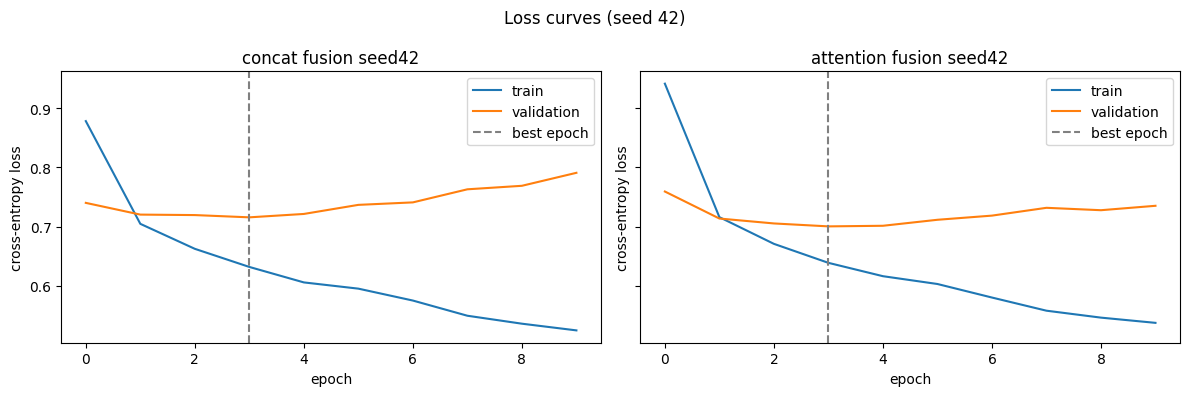

Mean attention weight per modality (validation, all three present):
    tabular   text  image
42    0.585  0.336  0.079
43    0.617  0.315  0.068
44    0.618  0.316  0.066

Mean attention weight by true price level (seed 42):
           tabular   text  image
budget       0.561  0.348  0.091
mid-range    0.592  0.333  0.075
premium      0.599  0.328  0.073


In [ ]:
import matplotlib.pyplot as plt

# Training diagnostics (Week 6): train vs validation loss. Validation loss going
# back up while training loss keeps falling means overfitting; the dashed line
# is the epoch whose weights were kept.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ["concat_fusion_seed42", "attention_fusion_seed42"]):
    h = histories[name]
    ax.plot(h["train_loss"], label="train")
    ax.plot(h["val_loss"], label="validation")
    ax.axvline(h["best_epoch"], ls="--", c="grey", label="best epoch")
    ax.set_title(name.replace("_", " "))
    ax.set_xlabel("epoch")
    ax.set_ylabel("cross-entropy loss")
    ax.legend()
plt.suptitle("Loss curves (seed 42)")
plt.tight_layout()
try:
    plt.savefig(RESULTS_DIR / "loss_curves.png", dpi=150)
except OSError as e:
    print(f"Couldn't save the figure: {e}")
plt.show()

# Which modality does attention fusion rely on? Average weight on validation
# listings that have all three modalities, per seed (a dominance check, Week 6)
full = (va & has_photo & has_text)
w = pd.DataFrame({seed: attn_weights[seed][full].mean(0) for seed in SEEDS}, index=MODS).T
print("Mean attention weight per modality (validation, all three present):")
print(w.round(3))
print("\nMean attention weight by true price level (seed 42):")
print(pd.DataFrame(attn_weights[42][full], columns=MODS)
      .groupby(df.loc[full, "price_level"].to_numpy()).mean().round(3))

## Saving the inputs and settings

The prepared inputs and every setting are saved so notebook 05 uses exactly the same features, and so the config table in the report comes straight from the code.

In [ ]:
# Save the prepared inputs so notebook 05 uses exactly the same features
try:
    np.savez_compressed(DATA_DIR / "model_inputs.npz", X_tab=X_tab, X_text=X_text,
                        X_img=X_img, y=y, split=split, has_photo=has_photo,
                        has_text=has_text)
    with open(RESULTS_DIR / "model_settings.json", "w") as f:
        json.dump({"text_input": TEXT_NAME, "early_fusion_C": best_C,
                   "tabular_dims": int(X_tab.shape[1]), "text_dims": int(X_text.shape[1]),
                   "image_dims": int(X_img.shape[1]), "seeds": SEEDS,
                   "projection_size": BEST["proj"], "dropout": BEST["dropout"],
                   "modality_dropout": 0.2, "optimiser": "Adam",
                   "learning_rate": BEST["lr"], "weight_decay": BEST["weight_decay"],
                   "batch": 256,
                   "max_epochs": 60, "early_stopping_patience": 6}, f, indent=2)
except OSError as e:
    raise RuntimeError(f"Couldn't save the model inputs: {e}")
print("Saved model_inputs.npz and model_settings.json")

Saved model_inputs.npz and model_settings.json


## Making sure everything is saved

Colab uploads to Drive in the background, so this waits until everything is actually on Drive before the runtime closes.

In [ ]:
from google.colab import drive
drive.flush_and_unmount()
print("Everything saved to Drive")

Everything saved to Drive
